In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

#绘制气泡图需要
from matplotlib.lines import Line2D
#绘制雷达图时需要
from math import pi

In [9]:
# 读取 RFM 视图
BASE_DIR = Path.cwd().parent
file_path = BASE_DIR / "data" / "processed" / "customer_rfm.csv"
rfm = pd.read_csv(file_path)

In [7]:
# 查看数据
print(rfm.head())

                 customer_unique_id  recency  frequency  monetary  \
0  0000366f3b9a7992bf8c76cfdf3221e2      112          1    129.90   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      115          1     18.90   
2  0000f46a3911fa3c0805444483337064      538          1     69.00   
3  0000f6ccb0745a6a4b88665a16c9f078      322          1     25.99   
4  0004aac84e0df4da2b147fca70cf8255      289          1    180.00   

   total_freight  
0          12.00  
1           8.29  
2          17.22  
3          17.63  
4          16.89  


In [10]:
# 查看数据规模
print(rfm.shape)

(93358, 4)


In [11]:
# 描述性统计分析1
print(rfm[['recency', 'frequency', 'monetary']].describe())

            recency     frequency      monetary
count  93358.000000  93358.000000  93358.000000
mean     238.478877      1.033420    141.621480
std      152.595054      0.209097    215.694014
min        1.000000      1.000000      0.850000
25%      115.000000      1.000000     47.650000
50%      219.000000      1.000000     89.730000
75%      347.000000      1.000000    154.737500
max      714.000000     15.000000  13440.000000


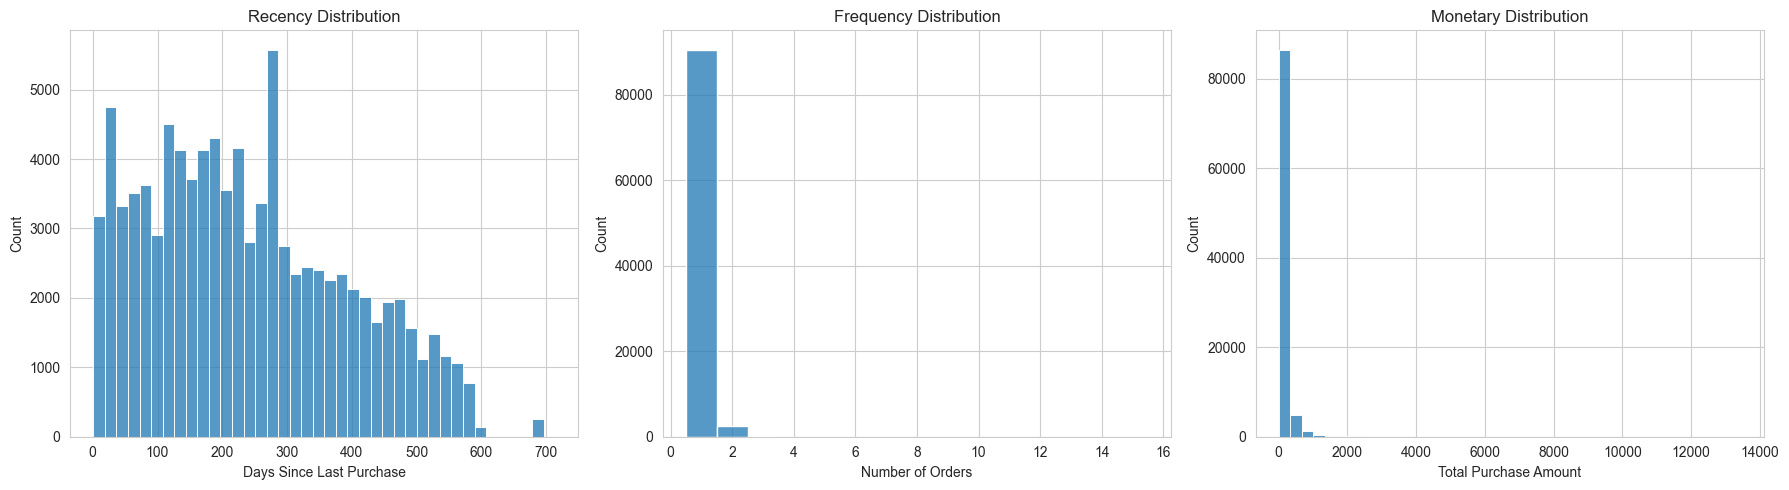

In [10]:
#绘制RFM指标分布图
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency
sns.histplot(
    data=rfm,
    x='recency',
    bins=40,
    ax=axes[0]
)
axes[0].set_title('Recency Distribution')
axes[0].set_xlabel('Days Since Last Purchase')

# Frequency
sns.histplot(
    data=rfm,
    x='frequency',
    bins=15,
    discrete=True,
    ax=axes[1]
)
axes[1].set_title('Frequency Distribution')
axes[1].set_xlabel('Number of Orders')

# Monetary
sns.histplot(
    data=rfm,
    x='monetary',
    bins=40,
    ax=axes[2]
)
axes[2].set_title('Monetary Distribution')
axes[2].set_xlabel('Total Purchase Amount')

plt.tight_layout()
plt.show()

In [11]:
# 查看更详细的分位数
quantiles = rfm[
    ['recency', 'frequency', 'monetary']
].quantile([0.1, 0.2, 0.4, 0.5, 0.6, 0.8, 0.9, 0.95, 0.99])

print(quantiles)

      recency  frequency  monetary
0.10     42.0        1.0    25.980
0.20     93.0        1.0    39.900
0.40    178.0        1.0    69.900
0.50    219.0        1.0    89.730
0.60    269.0        1.0   109.900
0.80    383.0        1.0   179.900
0.90    466.0        1.0   279.990
0.95    520.0        1.0   419.809
0.99    576.0        2.0  1004.990


In [12]:
#R:客户最近购买时间分布比较分散，整体上较大的R值对应的客户数量逐渐减少，用五分位数：
# 最近的20%----5分     20%-40%---4分    40%-60%---3分     60%-80%---2分    最久的20%---1分
#F:90%的客户购买次数都不超过1次，根据实际业务规则分组
#购买次数1次---1分     2-3次---3分     4次及以上---5分
#M:大部分客户消费金额集中在较低区间，只有少数客户消费金额特别高，少数高消费客户可能贡献了较大比例的商品销售额，用五分位数
#消费金额最高的20%---5分    60%-80%---4分    40%-60%---3分     20%-40%---2分    消费金额最低的20%---1分

In [13]:
#实现RFM评分

# 1. R评分：最近购买时间越短，得分越高
rfm['R_score'] = pd.qcut(
    #按照分位数划分数据
    rfm['recency'],
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)


# 2. F评分：根据业务规则进行评分
rfm['F_score'] = pd.cut(
    #按照指定数值区间划分数据
    rfm['frequency'],
    bins=[0, 1, 3, float('inf')],
    labels=[1, 3, 5]
).astype(int)


# 3. M评分：消费金额越高，得分越高
rfm['M_score'] = pd.qcut(
    ##按照分位数划分数据
    rfm['monetary'],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)


# 4. 计算RFM综合得分
rfm['RFM_score'] = (
    rfm['R_score'] +
    rfm['F_score'] +
    rfm['M_score']
)

# 5. 查看结果
print(rfm.head(10))

                 customer_unique_id  recency  frequency  monetary  \
0  0000366f3b9a7992bf8c76cfdf3221e2      112          1    129.90   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      115          1     18.90   
2  0000f46a3911fa3c0805444483337064      538          1     69.00   
3  0000f6ccb0745a6a4b88665a16c9f078      322          1     25.99   
4  0004aac84e0df4da2b147fca70cf8255      289          1    180.00   
5  0004bd2a26a76fe21f786e4fbd80607f      147          1    154.00   
6  00050ab1314c0e55a6ca13cf7181fecf      132          1     27.99   
7  00053a61a98854899e70ed204dd4bafe      183          1    382.00   
8  0005e1862207bf6ccc02e4228effd9a0      544          1    135.00   
9  0005ef4cd20d2893f0d9fbd94d3c0d97      171          1    104.90   

   total_freight  R_score  F_score  M_score  RFM_score  
0          12.00        4        1        4          9  
1           8.29        4        1        1          6  
2          17.22        1        1        2          4  
3          1

In [14]:
#检查评分结果
# 查看R评分分布
print("R Score Distribution:")
print(rfm['R_score'].value_counts().sort_index())

# 查看F评分分布
print("\nF Score Distribution:")
print(rfm['F_score'].value_counts().sort_index())

# 查看M评分分布
print("\nM Score Distribution:")
print(rfm['M_score'].value_counts().sort_index())

# 查看综合得分分布
print("\nRFM Score Distribution:")
print(rfm['RFM_score'].value_counts().sort_index())

R Score Distribution:
R_score
1    18605
2    18471
3    18723
4    18757
5    18802
Name: count, dtype: int64

F Score Distribution:
F_score
1    90557
3     2754
5       47
Name: count, dtype: int64

M Score Distribution:
M_score
1    19337
2    19436
3    17451
4    18632
5    18502
Name: count, dtype: int64

RFM Score Distribution:
RFM_score
3      4081
4      7581
5     11394
6     14202
7     18141
8     14421
9     11008
10     7807
11     3924
12      441
13      325
14       14
15       19
Name: count, dtype: int64


In [16]:
#建立客户分群规则
# 定义客户分群条件
conditions = [
    # 1. 核心高价值客户
    (rfm['R_score'] >= 4) &
    (rfm['F_score'] >= 3) &
    (rfm['M_score'] >= 4),

    # 2. 忠实复购客户
    (rfm['F_score'] >= 3),

    # 3. 潜力客户
    (rfm['R_score'] >= 4) &
    (rfm['F_score'] == 1) &
    (rfm['M_score'] >= 3),

    # 4. 有流失风险的高消费客户
    (rfm['R_score'] <= 2) &
    (rfm['M_score'] >= 4),

    # 5. 长期不活跃且低消费客户
    (rfm['R_score'] <= 2) &
    (rfm['F_score'] == 1) &
    (rfm['M_score'] <= 2)
]

# 对应的客户标签
segment_labels = [
    'Champions',
    'Loyal Customers',
    'Potential Loyalists',
    'At Risk',
    'Hibernating'
]

# 生成客户分群标签
rfm['customer_segment'] = np.select(
    conditions,
    segment_labels,
    default='Other Customers'
)

# 查看前10条
print(
    rfm[
        [
            'customer_unique_id',
            'recency',
            'frequency',
            'monetary',
            'R_score',
            'F_score',
            'M_score',
            'customer_segment'
        ]
    ].head(10)
)

                 customer_unique_id  recency  frequency  monetary  R_score  \
0  0000366f3b9a7992bf8c76cfdf3221e2      112          1    129.90        4   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      115          1     18.90        4   
2  0000f46a3911fa3c0805444483337064      538          1     69.00        1   
3  0000f6ccb0745a6a4b88665a16c9f078      322          1     25.99        2   
4  0004aac84e0df4da2b147fca70cf8255      289          1    180.00        2   
5  0004bd2a26a76fe21f786e4fbd80607f      147          1    154.00        4   
6  00050ab1314c0e55a6ca13cf7181fecf      132          1     27.99        4   
7  00053a61a98854899e70ed204dd4bafe      183          1    382.00        3   
8  0005e1862207bf6ccc02e4228effd9a0      544          1    135.00        1   
9  0005ef4cd20d2893f0d9fbd94d3c0d97      171          1    104.90        4   

   F_score  M_score     customer_segment  
0        1        4  Potential Loyalists  
1        1        1      Other Customers  
2        1  

In [17]:
# 按客户群体汇总业务指标
segment_analysis = (
    rfm.groupby('customer_segment', observed=True)
    #按客户标签分组
    .agg(
        customer_count=('customer_unique_id', 'count'),
        avg_recency=('recency', 'mean'),     #计算平均R、F、M值
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        total_revenue=('monetary', 'sum')    #统计各群体贡献的总收入
    )
    .reset_index()
)

# 计算客户数量占比
segment_analysis['customer_percentage'] = (
    segment_analysis['customer_count']
    / segment_analysis['customer_count'].sum() * 100
)

# 计算销售额贡献占比
segment_analysis['revenue_percentage'] = (
    segment_analysis['total_revenue']
    / segment_analysis['total_revenue'].sum() * 100
)

# 保留两位小数
numeric_columns = [
    'avg_recency',
    'avg_frequency',
    'avg_monetary',
    'total_revenue',
    'customer_percentage',
    'revenue_percentage'
]

segment_analysis[numeric_columns] = (
    segment_analysis[numeric_columns].round(2)
)

# 按客户数量降序排列
segment_analysis = segment_analysis.sort_values(
    'customer_count',
    ascending=False
)

print(segment_analysis)

      customer_segment  customer_count  avg_recency  avg_frequency  \
4      Other Customers           40023       201.58           1.00   
5  Potential Loyalists           21264        92.07           1.00   
2          Hibernating           15690       397.88           1.00   
0              At Risk           13580       395.97           1.00   
3      Loyal Customers            1860       286.88           2.08   
1            Champions             941        90.21           2.19   

   avg_monetary  total_revenue  customer_percentage  revenue_percentage  
4         89.38     3577420.79                42.87               27.06  
5        211.27     4492425.22                22.78               33.98  
2         41.03      643792.47                16.81                4.87  
0        278.31     3779450.88                14.55               28.59  
3        226.27      420865.64                 1.99                3.18  
1        326.83      307543.11                 1.01              

In [19]:
#数据可视化

#1. 设置绘图风格
sns.set_theme(style="whitegrid", context="notebook")

# 设置画布字体
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['font.size'] = 10

      customer_segment  customer_count  avg_recency  avg_frequency  \
1            Champions             941        90.21           2.19   
3      Loyal Customers            1860       286.88           2.08   
5  Potential Loyalists           21264        92.07           1.00   
0              At Risk           13580       395.97           1.00   
2          Hibernating           15690       397.88           1.00   
4      Other Customers           40023       201.58           1.00   

   avg_monetary  total_revenue  customer_percentage  revenue_percentage  
1        326.83      307543.11                 1.01                2.33  
3        226.27      420865.64                 1.99                3.18  
5        211.27     4492425.22                22.78               33.98  
0        278.31     3779450.88                14.55               28.59  
2         41.03      643792.47                16.81                4.87  
4         89.38     3577420.79                42.87              

In [ ]:
#2. 按业务价值排序
#将customer_segment列的普通字符串类型转化为有序分类数据，不同类别是有顺序的
#让后续所有图表的客户群体顺序保持一致，而不是每张图都按不同的顺序排列
segment_order = [
    'Champions',
    'Loyal Customers',
    'Potential Loyalists',
    'At Risk',
    'Hibernating',
    'Other Customers'
]

segment_analysis['customer_segment'] = pd.Categorical(
    segment_analysis['customer_segment'],
    categories=segment_order,
    ordered=True
)

segment_analysis = segment_analysis.sort_values(
    'customer_segment'
)

print(segment_analysis)

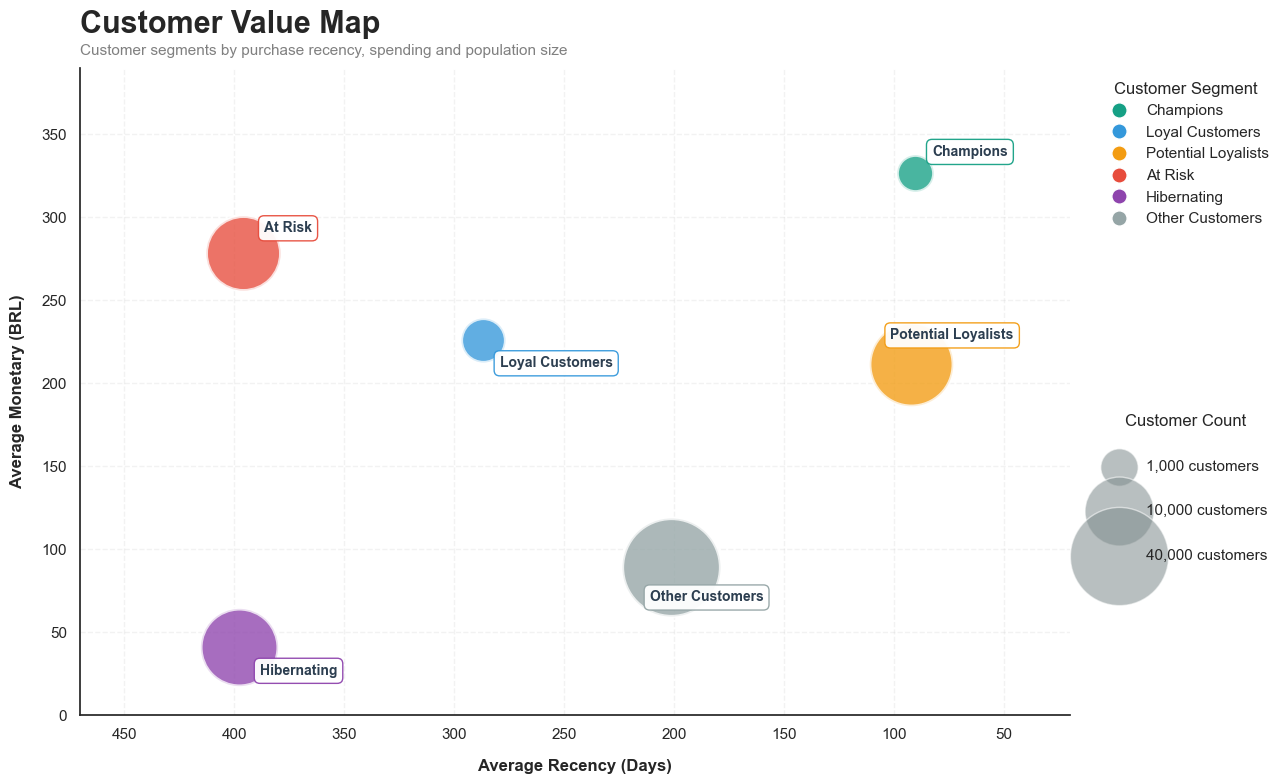

In [38]:
#3.绘制气泡图--客户价值地图

# 1. 设置绘图风格
sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(figsize=(13, 8))

# 2. 为六类客户设置不同颜色
segment_colors = {
    'Champions': '#16A085',
    'Loyal Customers': '#3498DB',
    'Potential Loyalists': '#F39C12',
    'At Risk': '#E74C3C',
    'Hibernating': '#8E44AD',
    'Other Customers': '#95A5A6'
}

# 3. 重新映射气泡大小
# 使用平方根缩放，避免最大群体的气泡过于突出
counts = segment_analysis['customer_count']

sqrt_counts = np.sqrt(counts)

bubble_sizes = (
    700
    + (sqrt_counts - sqrt_counts.min())
    / (sqrt_counts.max() - sqrt_counts.min())
    * 4300
)

# 4. 绘制不同客户群体
for i, row in enumerate(segment_analysis.itertuples()):

    ax.scatter(
        row.avg_recency,
        row.avg_monetary,
        s=bubble_sizes.iloc[i],
        color=segment_colors[row.customer_segment],
        alpha=0.78,
        edgecolors='white',
        linewidths=2.5,
        zorder=3
    )

# 5. 设置标签偏移，减少重叠
label_offsets = {
    'Champions': (12, 12),
    'Loyal Customers': (12, -20),
    'Potential Loyalists': (-15, 18),
    'At Risk': (15, 15),
    'Hibernating': (15, -20),
    'Other Customers': (-15, -25)
}

for row in segment_analysis.itertuples():

    offset = label_offsets[row.customer_segment]

    ax.annotate(
        row.customer_segment,
        xy=(row.avg_recency, row.avg_monetary),
        xytext=offset,
        textcoords='offset points',
        fontsize=10,
        fontweight='bold',
        color='#2C3E50',
        bbox=dict(
            boxstyle='round,pad=0.4',
            facecolor='white',
            edgecolor=segment_colors[row.customer_segment],
            alpha=0.95
        ),
        zorder=5
    )

# 6. 设置坐标轴
ax.invert_xaxis()

ax.set_xlim(470, 20)
ax.set_ylim(0, 390)

ax.set_xlabel(
    'Average Recency (Days)',
    fontsize=12,
    fontweight='bold',
    labelpad=12
)

ax.set_ylabel(
    'Average Monetary (BRL)',
    fontsize=12,
    fontweight='bold',
    labelpad=12
)

# 7. 标题与副标题
ax.set_title(
    'Customer Value Map',
    fontsize=22,
    fontweight='bold',
    loc='left',
    pad=25
)

ax.text(
    0,
    1.02,
    'Customer segments by purchase recency, spending and population size',
    transform=ax.transAxes,
    fontsize=11,
    color='gray'
)

# 8. 图例：客户群体颜色
color_legend = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=segment_colors[name],
        markeredgecolor='white',
        markersize=11,
        label=name
    )
    for name in segment_colors
]

legend1 = ax.legend(
    handles=color_legend,
    title='Customer Segment',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.add_artist(legend1)

# 9. 图例：气泡大小
size_values = [1000, 10000, 40000]

size_handles = [
    ax.scatter(
        [],
        [],
        s=700 + (
            np.sqrt(v) - sqrt_counts.min()
        ) / (
            sqrt_counts.max() - sqrt_counts.min()
        ) * 4300,
        color='#7F8C8D',
        alpha=0.55,
        edgecolors='white'
    )
    for v in size_values
]

ax.legend(
    handles=size_handles,
    labels=[f'{v:,} customers' for v in size_values],
    title='Customer Count',
    loc='center left',
    bbox_to_anchor=(1.02, 0.35),
    frameon=False,
    labelspacing=2
)

# 10. 美化背景
ax.grid(
    True,
    linestyle='--',
    alpha=0.25,
    zorder=0
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
#横轴表示平均客户购买时间，越往右说明购买时间越短，评分越高
#纵轴表示平均消费金额，越往上消费金额越高。气泡大小表示客户数量

                     R_score  F_score  M_score
customer_segment                              
Champions               4.52     3.07     4.68
Loyal Customers         2.46     3.02     3.88
Potential Loyalists     4.50     1.00     4.00
At Risk                 1.50     1.00     4.51
Hibernating             1.49     1.00     1.51
Other Customers         3.31     1.00     2.40


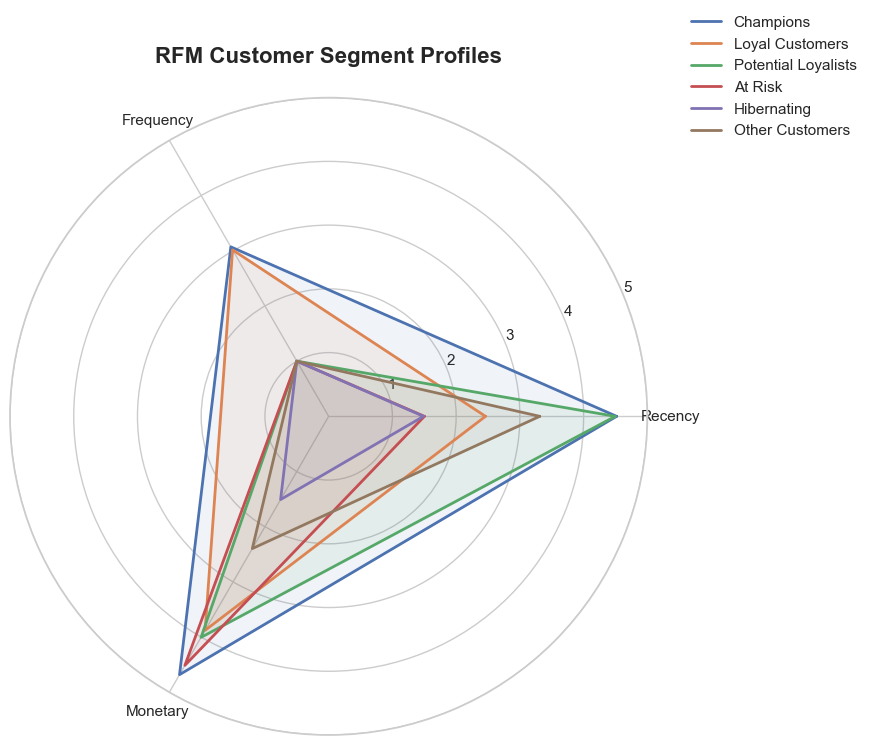

In [28]:
#4.雷达图---客户群体画像

#计算各群体的平均评分
radar_data = (
    rfm.groupby('customer_segment', observed=True)
    [['R_score', 'F_score', 'M_score']]
    .mean()
    .reindex(segment_order)
)

print(radar_data.round(2))

#绘制雷达图
#使用各群体的平均R、F、M值，而不是原始数据，消除量纲不同的影响

categories = ['Recency', 'Frequency', 'Monetary']

N = len(categories)

angles = [
    n / float(N) * 2 * pi
    for n in range(N)
]

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(9, 9),
    subplot_kw={'polar': True}
)

for segment in segment_order:

    values = radar_data.loc[segment].tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=segment
    )

    ax.fill(
        angles,
        values,
        alpha=0.08
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

ax.set_ylim(0, 5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.set_title(
    'RFM Customer Segment Profiles',
    fontsize=16,
    fontweight='bold',
    pad=25
)

ax.legend(
    loc='upper right',
    bbox_to_anchor=(1.35, 1.15),
    frameon=False
)

plt.tight_layout()
plt.show()

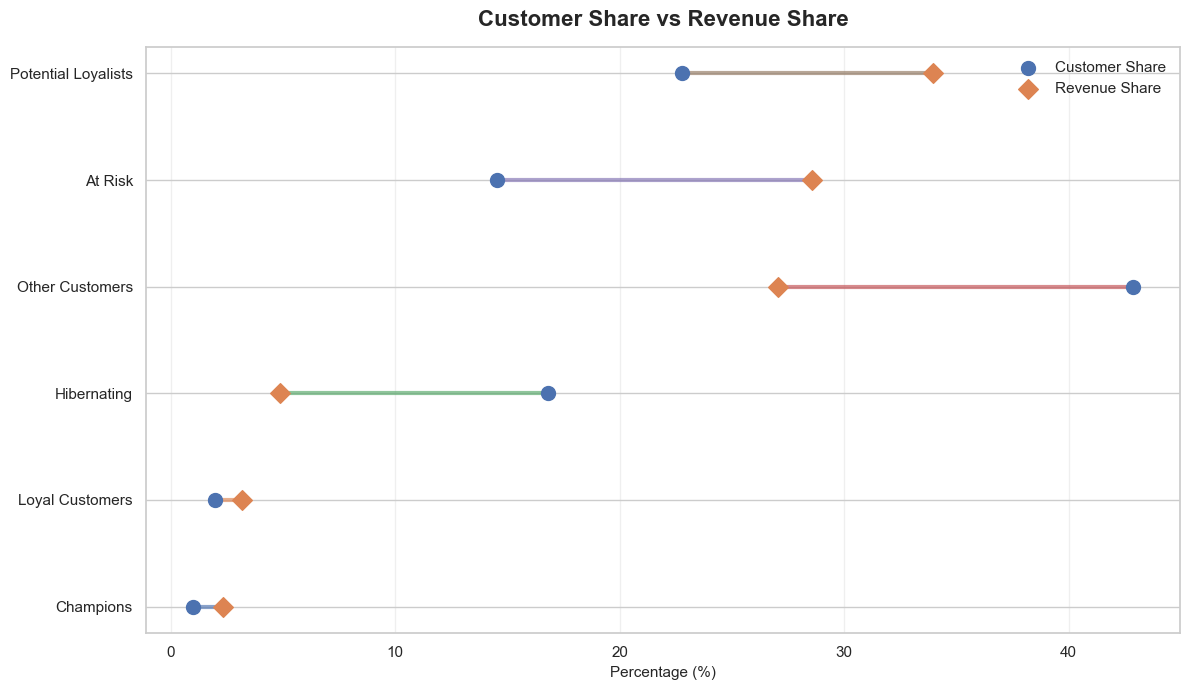

In [30]:
#4.哑铃图---客户占比与收入占比
plot_data = segment_analysis.sort_values(
    'revenue_percentage'
)

fig, ax = plt.subplots(figsize=(12, 7))

for i, row in enumerate(
    plot_data.itertuples()
):
    ax.plot(
        [row.customer_percentage, row.revenue_percentage],
        [i, i],
        linewidth=3,
        alpha=0.65
    )

ax.scatter(
    plot_data['customer_percentage'],
    range(len(plot_data)),
    s=100,
    label='Customer Share',
    zorder=3
)

ax.scatter(
    plot_data['revenue_percentage'],
    range(len(plot_data)),
    s=100,
    label='Revenue Share',
    marker='D',
    zorder=3
)

ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels(plot_data['customer_segment'])

ax.set_xlabel('Percentage (%)')

ax.set_title(
    'Customer Share vs Revenue Share',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.legend(frameon=False)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#雷达图可以直接反应某个客户群体贡献的收入，是否与其客户数量相匹配。如果收入占比大于客户占比，说明该群体的人均收入贡献高于总体平均水平，即如果某个群体收入占比的点在客户占比的点的右边，说明该群体收入贡献高于其人数占比。由图可知Potential Loyalists,at risk，Loyal Customers和Champions的收入贡献高于其人数占比，应重点维护

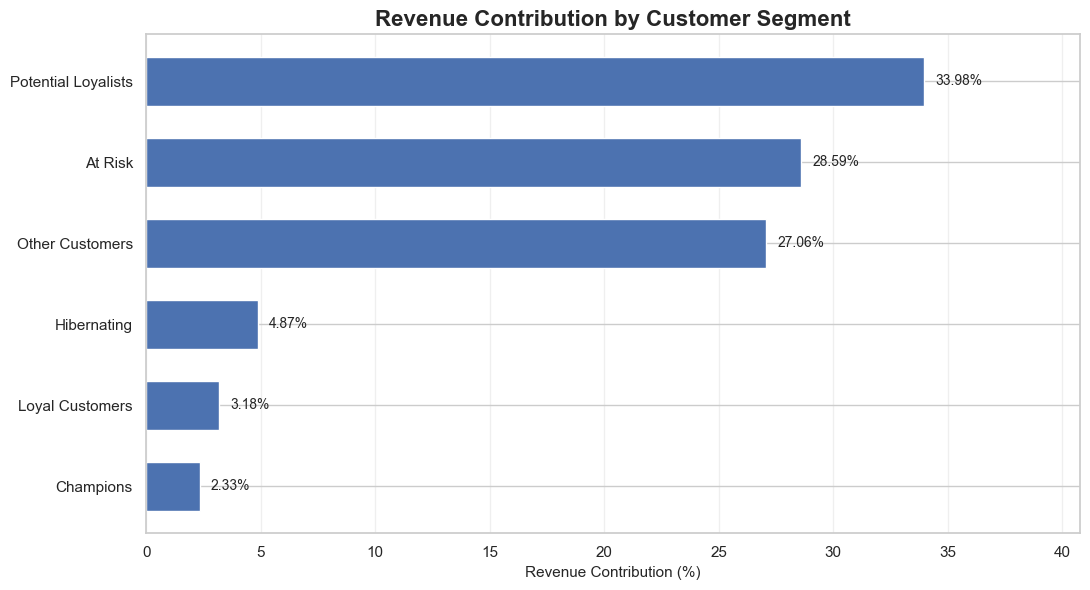

In [32]:
#5.条形图---每类客户贡献的商品销售额

revenue_data = segment_analysis.sort_values(
    'revenue_percentage',
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    revenue_data['customer_segment'],
    revenue_data['revenue_percentage'],
    height=0.6
)

# 在条形末端添加百分比
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}%',
        va='center',
        fontsize=10
    )

ax.set_xlabel('Revenue Contribution (%)')

ax.set_title(
    'Revenue Contribution by Customer Segment',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlim(
    0,
    revenue_data['revenue_percentage'].max() * 1.2
)

ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [2]:
#保存完成评分和分群后的rfm数据
from pathlib import Path
import os
BASE_DIR = Path(os.getcwd()).parent

OUTPUT_DIR = BASE_DIR / "data" / "processed"

save_path = OUTPUT_DIR / "rfm_scored.csv"
rfm.to_csv(save_path, index=False, encoding='utf-8-sig')

print(f"文件已成功保存到：{save_path}")

NameError: name 'rfm' is not defined